# SIM Intervention Demand Forecasting — Model Comparison and Selection

## 6.1. Objective

This stage compares five forecasting methods using the same chronological validation observations from 2021 through 2024: the historical same-weekday baseline, LightGBM, CatBoost, Linear Regression, and the fixed equal-weight Ensemble.

We will compare MAE, Bias, error variability, performance by division and year, and results on high-demand days. Graphs will help communicate the comparisons. We will make a provisional model selection without using the reserved 2025–2026 final test period.


## 6.2. Load and Match Baseline and Model Predictions

We will load the five model predictions exported from Stage 5 and the selected historical baseline from Stage 2. We will match observations using `Date` and `DIVISION`, verify equal actual counts, and check for duplicates and missing predictions before comparing methods.

The modeling dataset and the chronological schedule are also loaded for the later high-demand analysis.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the modeling dataset and validation schedule for high-demand analysis
df_modeling = pd.read_csv(
    "../../data/interim/final/SIM_Features_Modeling.csv", parse_dates=["Date"]
)
df_schedule = pd.read_csv(
    "../../data/interim/final/SIM_Chronological_Validation_Schedule.csv",
    parse_dates=["Validation_Start", "Validation_End", "Training_Cutoff"]
)

# Load Stage 5 predictions and Stage 2 baseline predictions
df_model_predictions = pd.read_csv(
    "../../data/interim/final/SIM_Model_Validation_Predictions.csv", parse_dates=["Date"]
)
df_baseline = pd.read_csv(
    "../../data/interim/final/SIM_Baseline_Validation_Predictions.csv", parse_dates=["Date"]
)

# Verify the keys before matching
assert not df_model_predictions.duplicated(["Date", "DIVISION"]).any()
assert not df_baseline.duplicated(["Date", "DIVISION"]).any()
assert len(df_model_predictions) == len(df_baseline) == 8760

# Match the historical baseline to all model predictions
df_four_models = df_model_predictions.merge(
    df_baseline[["Date", "DIVISION", "Intervention_Count", "Baseline_Prediction"]],
    on=["Date", "DIVISION"], how="inner", validate="one_to_one"
)

# Check that observed intervention counts match
assert len(df_four_models) == 8760
assert (df_four_models["Actual_Count"] == df_four_models["Intervention_Count"]).all()
df_four_models = df_four_models.drop(columns=["Intervention_Count"])

required_columns = [
    "Date", "DIVISION", "Actual_Count", "Baseline_Prediction",
    "LightGBM_Prediction", "CatBoost_Prediction", "Linear_Prediction",
    "Ensemble_Prediction"
]
assert df_four_models[required_columns].notna().all().all()
assert df_four_models["Date"].min() == pd.Timestamp("2021-01-01")
assert df_four_models["Date"].max() == pd.Timestamp("2024-12-30")

print("Validation months:", len(df_schedule))
print("Matched validation observations:", len(df_four_models))
print("Validation period:", df_four_models["Date"].min().date(), "to", df_four_models["Date"].max().date())
display(df_four_models[required_columns].head())


Validation months: 48
Matched validation observations: 8760
Validation period: 2021-01-01 to 2024-12-30


,Date,DIVISION,Actual_Count,Baseline_Prediction,LightGBM_Prediction,CatBoost_Prediction,Linear_Prediction,Ensemble_Prediction
0,2021-01-01,1,18.0,22.384615,23.222282,25.721262,26.262695,25.068747
1,2021-01-01,2,41.0,51.230769,53.352678,54.572590,52.819793,53.581687
2,2021-01-01,3,48.0,52.923077,55.816048,53.516553,51.549891,53.627497
3,2021-01-01,4,53.0,58.461538,59.123836,56.256852,56.753947,57.378212
4,2021-01-01,5,42.0,53.769231,57.046466,56.173112,55.034881,56.084820



### Methodological Observation

All five forecasting methods are evaluated using the same 8,760 division-day observations from January 1, 2021 to December 30, 2024.

Predictions are matched by date and division to ensure a fair comparison. The missing observations for December 31, 2024 are consistently excluded.

This ensures that differences in model performance are not caused by differences in the evaluation dataset.


## 6.3 Compare Forecasting Model Performance

We will compare the five forecasting methods using the same 8,760 division-day validation observations from 2021 through 2024.

The comparison will include Mean Absolute Error (MAE), prediction bias, absolute bias, and percentage improvement in MAE relative to the historical baseline.

These metrics will help evaluate whether the additional complexity of LightGBM and CatBoost produces meaningful improvements compared with Linear Regression.

Model selection will also consider performance across operational divisions and validation years before reaching a conclusion.

In [ ]:

# Identify the prediction column for each model
model_columns = {
    "Baseline": "Baseline_Prediction",
    "Linear Regression": "Linear_Prediction",
    "LightGBM": "LightGBM_Prediction",
    "CatBoost": "CatBoost_Prediction",
    "Ensemble": "Ensemble_Prediction"
}

# Store model evaluation results
model_results = []

# Calculate metrics for each model
for model_name, prediction_column in model_columns.items():

    errors = (
        df_four_models[prediction_column] -
        df_four_models["Actual_Count"]
    )

    model_results.append({
        "Model": model_name,
        "MAE": errors.abs().mean(),
        "Bias": errors.mean(),
        "Absolute_Bias": abs(errors.mean())
    })

# Create the comparison table
df_model_comparison = pd.DataFrame(model_results)

# Retrieve the baseline MAE
baseline_mae = df_model_comparison.loc[
    df_model_comparison["Model"] == "Baseline",
    "MAE"
].iloc[0]

# Calculate percentage improvement relative to baseline
df_model_comparison["MAE_Improvement_Percent"] = (
    (baseline_mae - df_model_comparison["MAE"]) /
    baseline_mae * 100
)

# Display the results, sorted by MAE
print("Five-Method Validation Comparison (2021-2024)")

display(
    df_model_comparison.sort_values("MAE").round(3)
)


Five-Method Validation Comparison (2021-2024)


,Model,MAE,Bias,Absolute_Bias,MAE_Improvement_Percent
4,Ensemble,8.029,-1.703,1.703,5.318
3,CatBoost,8.127,-1.768,1.768,4.164
2,LightGBM,8.147,-2.002,2.002,3.936
1,Linear Regression,8.384,-1.340,1.340,1.132
0,Baseline,8.480,-0.483,0.483,0.000


### Visualization — Overall MAE by Forecasting Method

This chart compares all five methods on the same observations. Lower MAE is better. The printed metrics table remains the precise reference.


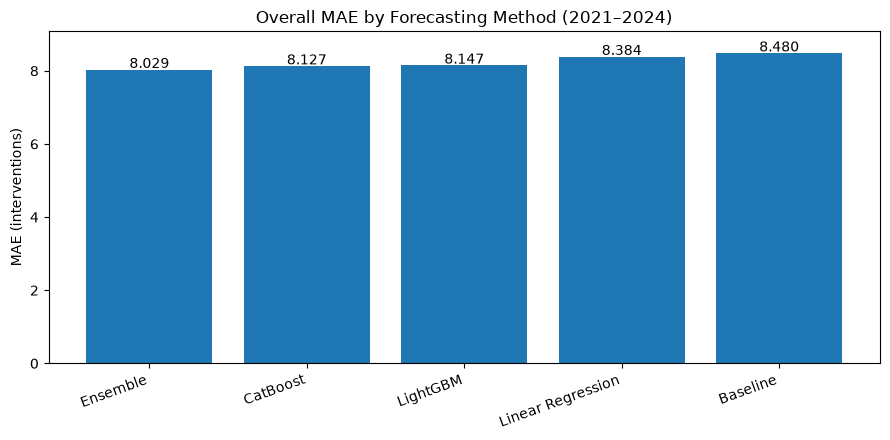

In [ ]:

# Compare overall MAE across all five methods
chart_data = df_model_comparison.sort_values("MAE")

plt.figure(figsize=(9, 4.5))

bars = plt.bar(chart_data["Model"], chart_data["MAE"])

# Display MAE values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.05,
        f"{height:.3f}",
        ha="center"
    )

plt.ylabel("MAE (interventions)")
plt.title("Overall MAE by Forecasting Method (2021–2024)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, chart_data["MAE"].max() + 0.6)

plt.tight_layout()
plt.show()



### Methodological Observation

All four machine learning methods achieved lower MAE than the historical baseline during the 2021–2024 validation period.

The Ensemble achieved the lowest MAE (8.029), improving the baseline MAE by 5.318%. However, its advantage over CatBoost was small (0.098 interventions per division-day).

The Baseline had the lowest absolute bias (0.483), while all four machine learning methods showed a stronger tendency to underestimate intervention demand.

These findings show that lower MAE does not necessarily imply lower systematic bias.

The Ensemble is currently the strongest candidate based on overall MAE, but the final model selection requires further analysis of performance across divisions and years, error variability, and high-demand days.



## 6.4 Compare Performance by Division and Year

We will compare the five forecasting methods separately by operational division and validation year.

The analysis will calculate Mean Absolute Error (MAE) for each model using the same matched observations.

We will identify the model with the lowest MAE in each division and year to assess whether the overall performance differences are consistent.

These results will help determine whether the additional complexity of gradient boosting models provides a meaningful and consistent benefit over Linear Regression and the historical baseline.

In [ ]:

# Store absolute prediction errors for each model
for model_name, prediction_column in model_columns.items():

    df_four_models[f"{model_name}_Absolute_Error"] = (
        df_four_models[prediction_column] -
        df_four_models["Actual_Count"]
    ).abs()

# Define the error columns
error_columns = [
    f"{model_name}_Absolute_Error"
    for model_name in model_columns
]

# Calculate MAE by operational division
division_comparison = (
    df_four_models.groupby("DIVISION")[error_columns].mean()
)

# Rename columns
division_comparison.columns = list(model_columns.keys())

# Identify the model with the lowest MAE
division_comparison["Best_Model"] = (
    division_comparison[list(model_columns.keys())].idxmin(axis=1)
)

print("MAE by Division:")
display(division_comparison.round(3))

# Extract the forecast year
df_four_models["Year"] = df_four_models["Date"].dt.year

# Calculate MAE by year
yearly_comparison = (
    df_four_models.groupby("Year")[error_columns].mean()
)

# Rename columns
yearly_comparison.columns = list(model_columns.keys())

# Identify the model with the lowest MAE
yearly_comparison["Best_Model"] = (
    yearly_comparison[list(model_columns.keys())].idxmin(axis=1)
)

print("\nMAE by Year:")
display(yearly_comparison.round(3))


MAE by Division:


,Baseline,Linear Regression,LightGBM,CatBoost,Ensemble,Best_Model
DIVISION,,,,,,
1,6.319,6.413,6.032,6.134,6.118,LightGBM
2,8.773,8.443,8.242,8.143,8.136,Ensemble
3,9.707,9.716,9.419,9.322,9.119,Ensemble
4,8.844,8.780,8.763,8.506,8.479,Ensemble
5,9.359,9.150,8.866,8.789,8.708,Ensemble
6,7.880,7.805,7.558,7.869,7.617,LightGBM



MAE by Year:


,Baseline,Linear Regression,LightGBM,CatBoost,Ensemble,Best_Model
Year,,,,,,
2021,7.255,7.292,7.187,7.123,7.080,Ensemble
2022,7.789,7.568,7.702,7.550,7.483,Ensemble
2023,10.719,10.619,9.755,9.958,9.756,LightGBM
2024,8.159,8.059,7.943,7.878,7.799,Ensemble


### Visualization — MAE by Division and Year

The first chart shows how model accuracy differs across divisions. The second displays annual MAE trends. These are comparison charts, not evidence of causality.


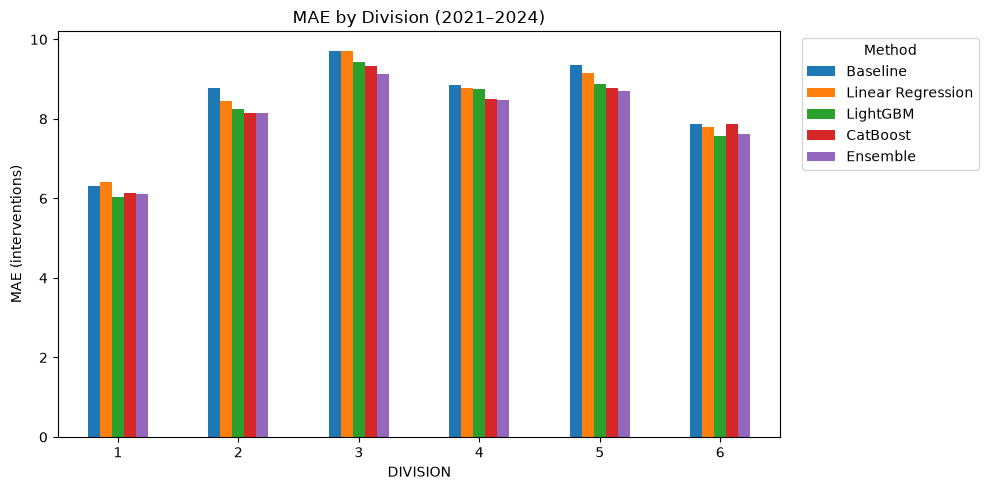

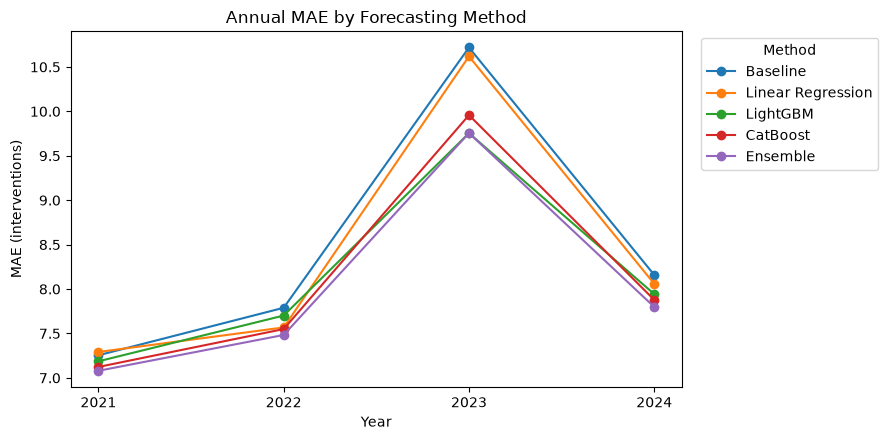

In [ ]:
# Compare MAE across operational divisions
plot_columns = list(model_columns.keys())
division_comparison[plot_columns].plot(kind="bar", figsize=(10, 5))
plt.ylabel("MAE (interventions)")
plt.xlabel("DIVISION")
plt.title("MAE by Division (2021–2024)")
plt.legend(title="Method", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Compare annual MAE over the validation period
yearly_comparison[plot_columns].plot(kind="line", marker="o", figsize=(9, 4.5))
plt.ylabel("MAE (interventions)")
plt.xlabel("Year")
plt.title("Annual MAE by Forecasting Method")
plt.xticks(yearly_comparison.index)
plt.legend(title="Method", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



### Methodological Observation

The Ensemble achieved the lowest MAE in four of the six operational divisions and in three of the four validation years.

LightGBM performed best in Divisions 1 and 6. It also achieved the lowest MAE in 2023, although its advantage over the Ensemble was only 0.001 interventions per division-day, based on rounded results.

The Ensemble outperformed the Baseline in every division and every validation year, showing consistent improvements across the evaluated groups.

All five methods experienced higher forecasting errors in 2023. The available results do not establish the cause of this increase.

These findings support the Ensemble as a strong candidate for model selection. However, the small differences between some methods and the variation across divisions and years must be considered alongside bias and error variability before making a final decision.


## 6.5 Compare Prediction Bias by Division and Year

We will compare prediction bias across operational divisions and validation years for all five forecasting methods.

Prediction bias is calculated as the average difference between predicted and actual intervention counts. Positive values indicate overestimation, while negative values indicate underestimation.

This analysis will help identify systematic forecasting differences that may not be visible when comparing MAE alone.

Bias will be considered alongside MAE, because a value close to zero does not necessarily indicate accurate predictions.

In [ ]:

# Calculate signed prediction errors for each model
for model_name, prediction_column in model_columns.items():

    df_four_models[f"{model_name}_Error"] = (
        df_four_models[prediction_column] -
        df_four_models["Actual_Count"]
    )

# Identify the signed error columns
bias_columns = [
    f"{model_name}_Error"
    for model_name in model_columns
]

# Calculate prediction bias by division
division_bias = (
    df_four_models.groupby("DIVISION")[bias_columns].mean()
)

# Use model names as column labels
division_bias.columns = list(model_columns.keys())

print("Prediction Bias by Division:")
display(division_bias.round(3))

# Calculate prediction bias by year
yearly_bias = (
    df_four_models.groupby("Year")[bias_columns].mean()
)

# Use model names as column labels
yearly_bias.columns = list(model_columns.keys())

print("\nPrediction Bias by Year:")
display(yearly_bias.round(3))


Prediction Bias by Division:


,Baseline,Linear Regression,LightGBM,CatBoost,Ensemble
DIVISION,,,,,
1,-0.337,-1.079,-1.373,-0.892,-1.114
2,-0.443,-1.251,-1.709,-0.867,-1.276
3,-0.597,-1.521,-3.313,-3.806,-2.880
4,-0.372,-1.200,-2.114,-2.565,-1.960
5,-0.365,-1.255,-2.050,-1.946,-1.750
6,-0.783,-1.732,-1.452,-0.530,-1.238



Prediction Bias by Year:


,Baseline,Linear Regression,LightGBM,CatBoost,Ensemble
Year,,,,,
2021,-0.245,-0.928,-0.934,-0.846,-0.903
2022,-1.187,-0.965,-2.419,-1.945,-1.776
2023,-0.111,-1.520,-3.645,-3.184,-2.783
2024,-0.387,-1.945,-1.009,-1.096,-1.350


### Visualization — Overall Prediction Bias

Positive values indicate average overprediction; negative values indicate average underprediction. A value near zero does not imply low MAE.


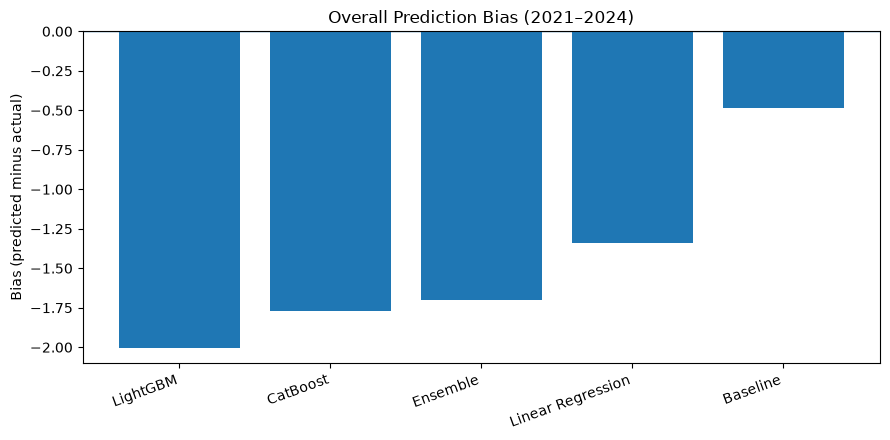

In [ ]:
# Compare signed bias by forecasting method
bias_chart = df_model_comparison.set_index("Model")["Bias"].sort_values()
plt.figure(figsize=(9, 4.5))
plt.bar(bias_chart.index, bias_chart.values)
plt.axhline(0, linewidth=1)
plt.ylabel("Bias (predicted minus actual)")
plt.title("Overall Prediction Bias (2021–2024)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()



### Methodological Observation

All five forecasting methods showed negative prediction bias across every operational division and validation year, indicating a consistent tendency to underestimate intervention demand on average.

The Baseline had the lowest overall absolute bias (0.483), while the Ensemble achieved the lowest MAE (8.029). This demonstrates that lower forecasting error does not necessarily mean lower systematic bias.

Division 3 showed the strongest underestimation for the Ensemble, with a bias of -2.880 interventions per day.

The machine learning models also showed greater underestimation in 2023, particularly LightGBM, CatBoost, and the Ensemble. This coincided with higher MAE values during the same year, although the available results do not establish the cause.

These findings highlight the importance of evaluating both MAE and bias when selecting a forecasting model. Systematic underestimation may be relevant for operational planning, even when overall forecasting accuracy improves.


## 6.6 Evaluate Prediction Error Variability

We will calculate the standard deviation of prediction errors for the five forecasting methods.

Standard deviation measures how much the signed prediction errors vary around their average value.

This analysis complements MAE and prediction bias by providing information about error variability.

We will calculate the results overall and separately for each operational division. The findings will help inform the provisional model selection without using the reserved final test period.

In [ ]:

# Calculate overall error standard deviation
variability_results = []

for model_name in model_columns:

    error_column = f"{model_name}_Error"

    variability_results.append({
        "Model": model_name,
        "Error_Std": df_four_models[error_column].std()
    })

# Create the overall variability table
df_error_variability = pd.DataFrame(variability_results)

print("Overall Prediction Error Variability:")
display(df_error_variability.round(3))

# Calculate error standard deviation by division
division_variability = (
    df_four_models.groupby("DIVISION")[bias_columns].std()
)

# Rename columns using model names
division_variability.columns = list(model_columns.keys())

print("\nError Standard Deviation by Division:")
display(division_variability.round(3))


Overall Prediction Error Variability:


,Model,Error_Std
0,Baseline,14.228
1,Linear Regression,14.205
2,LightGBM,13.845
3,CatBoost,13.830
4,Ensemble,13.712



Error Standard Deviation by Division:


,Baseline,Linear Regression,LightGBM,CatBoost,Ensemble
DIVISION,,,,,
1,14.601,14.693,14.176,14.225,14.228
2,13.547,13.332,13.011,12.939,12.941
3,17.332,17.498,17.027,16.850,16.732
4,13.137,13.142,13.147,12.672,12.674
5,15.320,15.157,14.599,14.714,14.557
6,10.528,10.432,10.109,10.471,10.209



### Methodological Observation

The Ensemble achieved the lowest overall error standard deviation (13.712), followed by CatBoost (13.830) and LightGBM (13.845).

This indicates that the Ensemble's prediction errors were slightly less variable around their average compared with the other forecasting methods.

However, the Ensemble did not achieve the lowest error standard deviation in every division. LightGBM performed best in Divisions 1 and 6, CatBoost in Divisions 2 and 4, and the Ensemble in Divisions 3 and 5.

Division 3 showed the highest error variability for the Ensemble (16.732), together with its highest MAE (9.119) and strongest negative bias (-2.880).

Error standard deviation complements MAE and bias, but it does not measure forecasting accuracy by itself. A model can have low error variability while still producing consistently inaccurate predictions.

The Ensemble remains the strongest candidate based on overall MAE and error variability. However, its systematic underestimation and the remaining high-demand analysis must be considered before provisional model selection.




## 6.7 Interim Comparison Review

The validation results from 2021 to 2024 provide the following findings:

- **Overall MAE:** The Ensemble achieved the lowest MAE (8.029), improving the Baseline by 5.318%.
- **Prediction Bias:** The Baseline had the lowest absolute bias (0.483). All five methods showed a tendency to underestimate intervention demand.
- **Error Variability:** The Ensemble achieved the lowest overall error standard deviation (13.712).
- **Performance by Division:** The Ensemble achieved the lowest MAE in four of the six operational divisions. LightGBM performed best in Divisions 1 and 6.
- **Performance by Year:** The Ensemble achieved the lowest MAE in 2021, 2022, and 2024. LightGBM performed slightly better in 2023.
- **2023 Results:** All five methods showed higher MAE in 2023 compared with the other validation years.

### Interim Assessment

The Ensemble is currently the strongest candidate based on overall MAE and error variability. However, it shows greater systematic underestimation than the Baseline, and its MAE advantage over CatBoost is relatively small.

The Ensemble uses fixed equal weights that were not tuned using validation outcomes.

No model is selected at this stage. The next sections will examine forecasting performance on actual high-demand days and evaluate a proposed high-demand warning rule.

The provisional model selection will be made after completing these additional analyses.



## 6.8 Evaluate Forecasting Errors on High-Demand Days

We will examine forecasting performance on days with unusually high recorded intervention counts.

High demand will be defined separately for each operational division using the 90th percentile of historical daily counts available within each monthly training window.

This approach accounts for differences in typical intervention volumes between divisions and prevents future validation outcomes from influencing the high-demand thresholds.

We will compare MAE and prediction bias across the five forecasting methods for observations classified as high demand.

The analysis is retrospective: actual intervention counts are used to identify high-demand observations for evaluation, not as information available when forecasts are generated.

In [ ]:

# Store high-demand thresholds for all validation months
high_demand_thresholds = []

for _, window in df_schedule.iterrows():

    # Select observations available at the monthly training cutoff
    training_data = df_modeling[
        df_modeling["Date"] <= window["Training_Cutoff"]
    ]

    # Calculate the 90th percentile separately for each division
    division_thresholds = (
        training_data.groupby("DIVISION")["Intervention_Count"]
        .quantile(0.90)
    )

    # Store thresholds for the validation month
    for division, threshold in division_thresholds.items():

        high_demand_thresholds.append({
            "Validation_Month": window["Validation_Start"],
            "DIVISION": division,
            "High_Demand_Threshold": threshold
        })

# Create a threshold dataset
df_thresholds = pd.DataFrame(high_demand_thresholds)

# Display verification results
print("Monthly validation windows:", len(df_schedule))
print("Threshold records:", len(df_thresholds))
print("Missing thresholds:", df_thresholds["High_Demand_Threshold"].isna().sum())

print("\nFirst six thresholds:")
display(df_thresholds.head(6))


Monthly validation windows: 48
Threshold records: 288
Missing thresholds: 0

First six thresholds:


,Validation_Month,DIVISION,High_Demand_Threshold
0,2021-01-01,1,30.0
1,2021-01-01,2,59.0
2,2021-01-01,3,66.0
3,2021-01-01,4,67.0
4,2021-01-01,5,63.0
5,2021-01-01,6,47.0



### Methodological Observation

High-demand thresholds were calculated separately for each operational division using the 90th percentile of historical daily intervention counts.

The thresholds were updated for each monthly validation window using data available through its training cutoff.

All 48 validation windows were verified to respect the D-3 cutoff rule. A total of 288 thresholds were generated, with no missing values.

This approach prevents future validation observations from being used to calculate historical high-demand thresholds.

These thresholds are statistical reference values, not officially established operational thresholds from SIM.



## 6.9 Identify High-Demand Validation Observations

We will identify high-demand observations within the 2021–2024 validation period.

Each division-day observation will be matched with the 90th-percentile threshold calculated from the historical training data available at the beginning of its validation month.

An observation will be classified as high demand when its actual intervention count is greater than or equal to the corresponding threshold.

Actual intervention counts will be used only for retrospective evaluation. This classification does not represent a model-generated high-demand warning.

In [ ]:

# Create the validation month identifier
df_four_models["Validation_Month"] = (
    df_four_models["Date"].dt.to_period("M").dt.to_timestamp()
)

# Match each observation with its monthly division threshold
df_high_demand = pd.merge(
    df_four_models,
    df_thresholds,
    on=["Validation_Month", "DIVISION"],
    how="left",
    validate="many_to_one"
)

# Identify actual high-demand observations
df_high_demand["Is_High_Demand"] = (
    df_high_demand["Actual_Count"] >=
    df_high_demand["High_Demand_Threshold"]
)

# Verify the classification
print("Total validation observations:", len(df_high_demand))

print(
    "Missing thresholds:",
    df_high_demand["High_Demand_Threshold"].isna().sum()
)

print(
    "High-demand observations:",
    df_high_demand["Is_High_Demand"].sum()
)

print(
    "High-demand percentage:",
    round(df_high_demand["Is_High_Demand"].mean() * 100, 2)
)

# Count high-demand observations by division
print("\nHigh-demand observations by division:")
display(
    df_high_demand.groupby("DIVISION")["Is_High_Demand"].sum()
)


Total validation observations: 8760
Missing thresholds: 0
High-demand observations: 1916
High-demand percentage: 21.87

High-demand observations by division:


DIVISION
1    366
2    306
3    322
4    271
5    286
6    365
Name: Is_High_Demand, dtype: int64

In [ ]:

# Review the first six validation windows and training cutoffs
display(
    df_schedule[
        ["Validation_Start", "Validation_End", "Training_Cutoff"]
    ].head(6)
)

# Check that every cutoff precedes its validation window
assert (
    df_schedule["Training_Cutoff"] <
    df_schedule["Validation_Start"]
).all()

print("All training cutoffs precede validation.")


,Validation_Start,Validation_End,Training_Cutoff
0,2021-01-01,2021-01-31,2020-12-29
1,2021-02-01,2021-02-28,2021-01-29
2,2021-03-01,2021-03-31,2021-02-26
3,2021-04-01,2021-04-30,2021-03-29
4,2021-05-01,2021-05-31,2021-04-28
5,2021-06-01,2021-06-30,2021-05-29


All training cutoffs precede validation.


In [ ]:
assert (
    df_schedule["Validation_Start"]
    - df_schedule["Training_Cutoff"]
    == pd.Timedelta(days=3)
).all()

print("All 48 validation windows respect the D-3 cutoff.")

All 48 validation windows respect the D-3 cutoff.



### Methodological Observation

A total of 1,916 out of 8,760 validation observations (21.87%) were classified as high demand using the historical 90th percentile thresholds.

This percentage can exceed 10% because the thresholds were calculated using earlier historical observations and applied to later validation periods. The classification also includes observations equal to the threshold.

High-demand observations were identified using actual intervention counts for retrospective evaluation only.

This classification does not demonstrate that the forecasting models can identify high-demand days in advance. That capability will be evaluated separately.



## 6.10 Compare Forecasting Performance on High-Demand Days

We will compare the five forecasting methods using the validation observations classified as high demand.

For each method, we will calculate Mean Absolute Error (MAE) and prediction bias within the high-demand subset.

We will also examine the results by operational division to identify differences in forecasting performance.

Because high-demand observations are identified using actual intervention counts, this analysis measures retrospective forecasting errors on high-demand days. It does not measure the models' ability to issue high-demand warnings before those days occur.

The results will complement the overall validation metrics and help assess whether the selected model performs adequately during periods of elevated intervention workload.

In [ ]:

# Select observations with actual high demand
df_high_demand_only = df_high_demand[
    df_high_demand["Is_High_Demand"]
].copy()

# Store performance results
high_demand_results = []

# Evaluate each forecasting method
for model_name, prediction_column in model_columns.items():

    # Calculate prediction errors
    errors = (
        df_high_demand_only[prediction_column] -
        df_high_demand_only["Actual_Count"]
    )

    # Store MAE and Bias
    high_demand_results.append({
        "Model": model_name,
        "MAE": errors.abs().mean(),
        "Bias": errors.mean()
    })

# Create the comparison table
df_high_demand_metrics = pd.DataFrame(high_demand_results)

print("High-Demand Model Comparison")
print("Observations:", len(df_high_demand_only))

display(
    df_high_demand_metrics.sort_values("MAE").round(3)
)

# Calculate MAE by division
division_high_demand_mae = pd.DataFrame()

for model_name, prediction_column in model_columns.items():

    # Calculate absolute errors
    df_high_demand_only[f"{model_name}_Absolute_Error"] = (
        df_high_demand_only[prediction_column] -
        df_high_demand_only["Actual_Count"]
    ).abs()

    # Calculate MAE for each division
    division_high_demand_mae[model_name] = (
        df_high_demand_only.groupby("DIVISION")[
            f"{model_name}_Absolute_Error"
        ].mean()
    )

print("\nHigh-Demand MAE by Division:")
display(division_high_demand_mae.round(3))


High-Demand Model Comparison
Observations: 1916


,Model,MAE,Bias
0,Baseline,15.366,-15.107
4,Ensemble,15.772,-15.301
1,Linear Regression,16.026,-14.544
3,CatBoost,16.078,-15.799
2,LightGBM,16.179,-15.559



High-Demand MAE by Division:


,Baseline,Linear Regression,LightGBM,CatBoost,Ensemble
DIVISION,,,,,
1,11.441,12.374,11.951,11.607,11.901
2,16.239,16.419,16.674,15.954,16.104
3,18.085,19.902,21.004,21.616,20.043
4,17.204,17.293,18.607,19.088,17.974
5,18.311,18.123,18.782,18.967,18.141
6,12.497,13.356,11.902,11.281,12.117


### Visualization — MAE on Actual High-Demand Days

This view focuses only on days classified retrospectively as high demand, using the thresholds defined earlier.


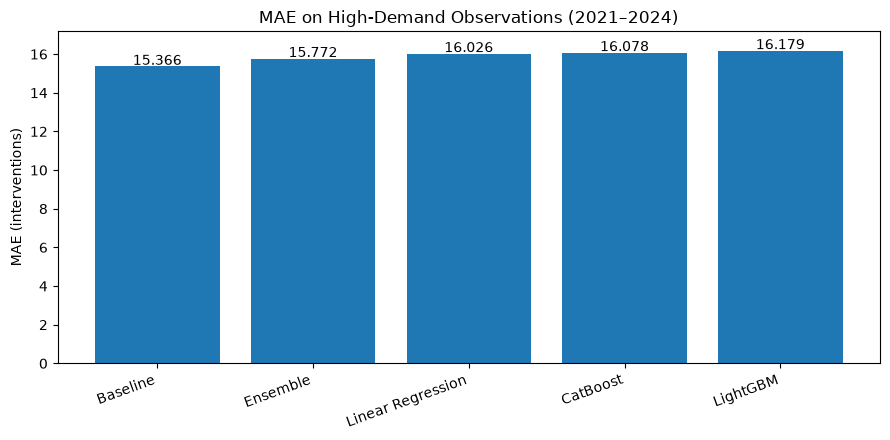

In [ ]:

# Compare MAE on actual high-demand observations
high_mae = df_high_demand_metrics.sort_values("MAE")

plt.figure(figsize=(9, 4.5))

bars = plt.bar(high_mae["Model"], high_mae["MAE"])

# Display MAE values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.08,
        f"{height:.3f}",
        ha="center"
    )

plt.ylabel("MAE (interventions)")
plt.title("MAE on High-Demand Observations (2021–2024)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, high_mae["MAE"].max() + 1)

plt.tight_layout()
plt.show()



### Methodological Observation

The evaluation included 1,916 observations classified as high demand using historical division-specific thresholds.

The Baseline achieved the lowest MAE on actual high-demand observations (15.366), followed by the Ensemble (15.772).

This contrasts with the overall validation results, where the Ensemble achieved the lowest MAE (8.029).

All five methods showed substantial negative bias during high-demand observations. The Ensemble had an average bias of -15.301 interventions, indicating systematic underestimation within this subset.

The Ensemble did not achieve the lowest high-demand MAE in any of the six operational divisions.

These results show that improvements in overall forecasting accuracy do not necessarily translate into better performance during periods of unusually high demand.

High-demand observations were identified retrospectively using actual intervention counts. Therefore, these results measure forecasting accuracy on high-demand days, not the ability to identify those days in advance.

The Ensemble remains the leading candidate based on overall MAE, but its high-demand performance is an important limitation to consider during model selection.


## 6.11 Evaluate High-Demand Warning Detection

We will evaluate whether the five forecasting methods could identify high-demand observations using their predicted intervention counts.

A high-demand warning will be issued when a model's predicted count meets or exceeds the historical 90th-percentile threshold for the corresponding division and validation month.

We will calculate recall, precision, and the number of warnings for each method.

Recall measures the proportion of actual high-demand observations correctly identified. Precision measures the proportion of issued warnings that correspond to actual high demand.

This analysis evaluates a proposed warning rule retrospectively. The threshold is an analytical definition of elevated demand, not an established SIM operational alert threshold.

In [ ]:

# Store warning detection results
warning_results = []

# Count actual high-demand observations
actual_high_demand = df_high_demand["Is_High_Demand"]
total_high_demand = actual_high_demand.sum()

for model_name, prediction_column in model_columns.items():

    # Identify predictions that exceed the historical threshold
    predicted_high_demand = (
        df_high_demand[prediction_column] >=
        df_high_demand["High_Demand_Threshold"]
    )

    # Count correctly detected high-demand observations
    correct_warnings = (
        predicted_high_demand & actual_high_demand
    ).sum()

    # Count all warnings issued
    total_warnings = predicted_high_demand.sum()

    # Calculate recall and precision
    recall = correct_warnings / total_high_demand

    if total_warnings > 0:
        precision = correct_warnings / total_warnings
    else:
        precision = np.nan

    warning_results.append({
        "Model": model_name,
        "Warnings": total_warnings,
        "Correct_Warnings": correct_warnings,
        "Recall": recall,
        "Precision": precision
    })

# Create the comparison table
df_warning_metrics = pd.DataFrame(warning_results)

print("Actual high-demand observations:", total_high_demand)
print("\nHigh-Demand Warning Detection:")
display(df_warning_metrics.round(3))



Actual high-demand observations: 1916

High-Demand Warning Detection:


,Model,Warnings,Correct_Warnings,Recall,Precision
0,Baseline,539,213,0.111,0.395
1,Linear Regression,471,198,0.103,0.420
2,LightGBM,318,160,0.084,0.503
3,CatBoost,359,174,0.091,0.485
4,Ensemble,319,165,0.086,0.517


### Visualization — High-Demand Warning Recall and Precision

Recall and precision display different aspects of the proposed warning rule. A high value in one metric does not guarantee a high value in the other.


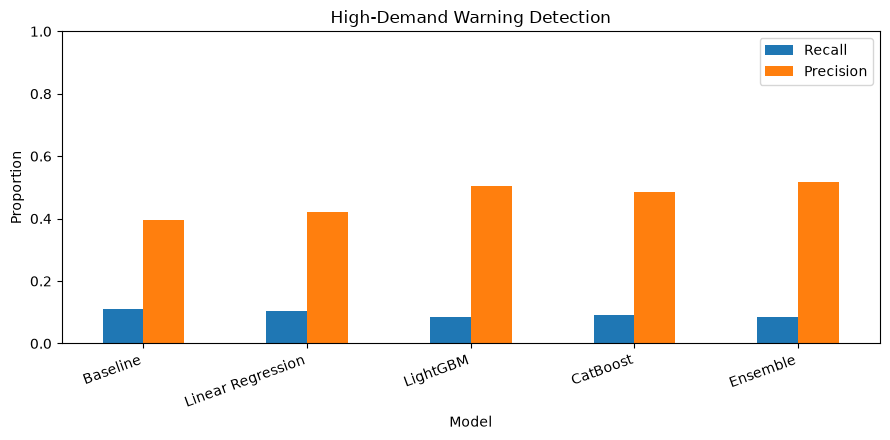

In [ ]:
# Compare the proposed warning rule across forecasting methods
warning_plot = df_warning_metrics.set_index("Model")[["Recall", "Precision"]]
warning_plot.plot(kind="bar", figsize=(9, 4.5))
plt.ylabel("Proportion")
plt.ylim(0, 1)
plt.title("High-Demand Warning Detection")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()



### Methodological Observation

High-demand warning detection was evaluated by comparing each model's predicted intervention count with the historical division-specific 90th percentile threshold.

The Baseline achieved the highest recall (11.1%), correctly identifying 213 of the 1,916 actual high-demand observations.

The Ensemble achieved the highest precision (51.7%), with 165 correct warnings out of 319 warnings issued. However, its recall was only 8.6%, meaning that 1,751 actual high-demand observations were not detected.

All five methods showed low recall, ranging from 8.4% to 11.1%.

These results reveal a limitation of using the current forecasting predictions and historical P90 thresholds as a high-demand warning system.

The models were trained to predict intervention counts, not specifically to maximize high-demand detection.

The Ensemble remains the leading candidate for overall forecasting accuracy, but its current warning detection performance is insufficient to support reliable high-demand alerts.

Warning detection should therefore be treated as an exploratory secondary analysis, separate from the primary forecasting objective.



## 6.12 Final Validation Conclusion and Provisional Model Selection

### Overall Validation Results

Five forecasting methods were evaluated using 8,760 division-day observations from 2021 to 2024.

The Ensemble achieved the lowest overall MAE (8.029), representing a 5.318% improvement over the Baseline (8.480).

The Ensemble also achieved the lowest overall error standard deviation (13.712). It obtained the lowest MAE in four of the six operational divisions and in three of the four validation years.

However, its advantage over CatBoost was relatively small, with an MAE difference of 0.098 interventions per division-day.

### Prediction Bias and Error Variability

All five methods showed negative prediction bias.

The Baseline had the lowest overall absolute bias (0.483), while the Ensemble had a bias of -1.703.

Although the Ensemble achieved better overall MAE and error variability, it showed a stronger tendency to underestimate intervention demand than the Baseline.

### High-Demand Performance

The evaluation identified 1,916 high-demand observations using historical division-specific 90th percentile thresholds.

The Baseline achieved the lowest MAE on these observations (15.366), followed by the Ensemble (15.772).

All five methods showed substantial underestimation during high-demand observations.

The proposed high-demand warning rule also produced low recall across all methods.

The Ensemble achieved the highest precision (51.7%), but its recall was only 8.6%.

These results indicate that the current forecasting methods and warning rule are not reliable for identifying most high-demand observations in advance.

### Provisional Model Selection

**Selected model: Fixed Equal-Weight Ensemble**

The Ensemble is provisionally selected because it achieved the lowest overall MAE, which is the primary evaluation metric established for this project.

It also achieved the lowest overall error variability and demonstrated consistent MAE improvements over the Baseline across all divisions and validation years.

The Ensemble uses fixed equal weights that were not optimized using validation outcomes.

However, its improvement over CatBoost is small. The additional complexity of maintaining multiple models may not be justified in every practical application.

CatBoost remains a simpler alternative with competitive forecasting performance.

### Limitations

- The Ensemble shows systematic underestimation of intervention demand.
- The Baseline performs better on actual high-demand observations.
- The proposed high-demand warning rule has low recall and should not be treated as a reliable operational alert system.
- The historical high-demand thresholds are analytical definitions, not established SIM operational thresholds.
- The additional complexity of the Ensemble has not been evaluated against production costs or operational requirements.
- Forecasting accuracy alone does not demonstrate operational effectiveness.

### Next Step: Final Testing

The Ensemble will proceed to final testing using the reserved 2025–2026 test period.

The final evaluation will examine whether its validation performance generalizes to previously unseen data.

The Baseline and individual forecasting models will remain available as reference methods for comparison.

No model selection changes will be made using the reserved test results. Any further adjustments would require a separate development and evaluation process.
